# K02 — Global porphyry-Cu paleo-prospectivity through subduction kinematics


**Cluster K: Mineral exploration.**
**A pyGMT modernisation of the Butterworth et al. (2016) spatio-temporal subduction-kinematics methodology applied to a global porphyry-Cu compilation. Reconstructs each deposit to its mineralisation age under Zahirovic 2022, samples reconstructed convergence rate / subduction-zone proximity / segment age at the paleo-position, and builds the per-deposit feature stack used by reconstruction-driven ML prospectivity classifiers.**

## What this notebook produces

K01 and K05 each focus on a regional porphyry province (SW Pacific arc; North American Cordillera). K02 zooms out to the global record and asks the methodological question: when porphyry deposits form, what subduction kinematics is contemporaneously active above them? The notebook reconstructs the 539 deposits of the USGS global porphyry copper database (Singer et al., 2008) that formed within the 410 Myr span of the Zahirovic 2022 model, samples a kinematic feature stack at each paleo-position, and renders (i) a global paleogeographic map at three representative ages showing the deposit distribution under the contemporaneous subduction geometry, (ii) histograms of per-deposit paleo-distance to nearest trench and reconstructed convergence rate at the closest trench segment, and (iii) the bivariate scatter of distance versus convergence rate that anchors the Butterworth et al. (2016) prospectivity classifier.

**Audience**: postgrad → researcher.
**Difficulty**: ★★★.

## Learning objectives

- Reconstruct a global ore-deposit compilation under a published plate model at each deposit's individual mineralisation age.
- Sample reconstructed subduction-zone segments for kinematic properties (convergence rate, segment age) at the closest segment to each deposit using `pygplates.tessellate_subduction_zones`.
- Build a per-deposit feature stack ready for a reconstruction-driven prospectivity classifier.
- Recognise the spatio-temporal envelope ("porphyry-generating distance × convergence rate" window) that the global compilation occupies.

## Prerequisites and runtime

- **Plate model**: Zahirovic 2022.
- **Data**: `data/porphyry_cu_global/global_porphyry_cu.csv` — the 576 deposits with a published age of mineralisation in the USGS global porphyry copper database (Singer et al., 2008), bundled with the suite.
- **Python**: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`.


## Data availability

This notebook reads `data/porphyry_cu_global/global_porphyry_cu.csv`, bundled with the suite. It holds every deposit with a published age of mineralisation (576 of 690) in the USGS database *Porphyry copper deposits of the world* (Singer et al., 2008; U.S. Geological Survey Open-File Report 2008-1155, public domain, `https://pubs.usgs.gov/of/2008/1155/`), with location, age, subtype (porphyry Cu, Cu-Au or Cu-Mo), ore tonnage and average grades. `tools/build_porphyry_cu_global.py` rebuilds the file from the USGS release; `data/porphyry_cu_global/README.md` describes the columns.

Related compilations:

- **Mutschler et al. (1999)**: giant porphyry-related metal camps of the world, USGS Open-File Report 99-556 — `https://pubs.usgs.gov/of/1999/of99-556/`
- **EarthByte porphyry_copper_spatiotemporal_exploration**: the Butterworth et al. (2016) study repository at `https://github.com/EarthByte/porphyry_copper_spatiotemporal_exploration`.

In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML

# Library versions (printed for reproducibility)
try:
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration

In [2]:
# === USER CONFIGURATION =====================================================
DEPOSITS_CSV   = "data/porphyry_cu_global/global_porphyry_cu.csv"
MODEL_NAME     = "Zahirovic2022"
SNAPSHOT_TIMES = (10.0, 50.0, 150.0)   # Ma — three representative paleo-maps
ANCHOR_PLATE_ID = 0
TRENCH_SAMPLE_SPACING_DEG = 0.5        # spacing of the trench samples (degrees, about 55 km)
NEAR_TRENCH_KM = 1000.0                # distance cutoff for "near-trench"
# ============================================================================


## 1. Load the global compilation

In [3]:
# Cell 2 — load
dep = pd.read_csv(DEPOSITS_CSV, comment="#")
dep.columns = [c.strip() for c in dep.columns]
print(f"  loaded {len(dep)} deposits | ages {dep.age_ma.min():g}–{dep.age_ma.max():g} Ma | "
      f"subtypes {dep.commodity.value_counts().to_dict()}")
dep.head()

  loaded 576 deposits | ages 1.15–3234 Ma | subtypes {'Cu': 397, 'Cu-Au': 121, 'Cu-Mo': 58}


,deposit_id,name,country,lon,lat,age_ma,age_range,subtype,commodity,tonnage_mt,cu_pct,mo_pct,au_gt,ag_gt
0,539,Ok Tedi,Papua New Guinea,141.13333,-5.20000,1.15,1.2–1.1,20c,Cu-Au,854.0,0.640,0.0110,0.78,0.00
1,487,Far Southeast-Bato Tabio,Philippines,120.78333,16.85833,1.35,1.6–1.1,20c,Cu-Au,650.0,0.650,0.0000,1.30,0.93
2,496,Santo Tomas II,Philippines,120.62250,16.26306,1.50,1.5,20c,Cu-Au,449.0,0.375,0.0005,0.70,1.50
3,558,Koloula,Solomon Islands,160.03333,-9.78333,2.00,2.4–1.5,17,Cu,50.0,0.170,0.0000,0.00,0.00
4,495,Kennon South East/Black Mountain,Philippines,120.60000,16.36667,2.10,2.1,17,Cu,62.0,0.378,0.0130,0.33,4.00


## 2. Reconstruct each deposit to its mineralisation age

In [4]:
# Cell 3 — per-deposit paleo-positions
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID)

# Keep the deposits that formed within the model's time span
MODEL_MAX_AGE = float(model.get_big_time())
n_all = len(dep)
dep = dep[dep.age_ma <= MODEL_MAX_AGE].reset_index(drop=True)
print(f"  {len(dep)} of {n_all} deposits formed within the {MODEL_MAX_AGE:.0f} Myr span of {MODEL_NAME}")

# Assign each deposit to the plate it sits on today (static polygons), then rotate it
# to its own mineralisation age with that plate's finite rotation.
pts = gplately.Points(recon, dep["lon"].values, dep["lat"].values, anchor_plate_id=ANCHOR_PLATE_ID)
dep["plate_id"] = np.asarray(pts.plate_id, dtype=int)
paleo = []
for r in dep.itertuples():
    rot = recon.rotation_model.get_rotation(float(r.age_ma), int(r.plate_id), anchor_plate_id=ANCHOR_PLATE_ID)
    paleo.append((rot * pygplates.PointOnSphere(r.lat, r.lon)).to_lat_lon())
dep["paleo_lat"], dep["paleo_lon"] = zip(*paleo)
print(f"  reconstructed {len(dep)} deposits on {dep.plate_id.nunique()} plates")

  539 of 576 deposits formed within the 410 Myr span of Zahirovic2022


  reconstructed 539 deposits on 88 plates


## 3. Per-deposit kinematic sampling at the closest contemporaneous trench

In [5]:
# Cell 4 — sample trench segments at each deposit's paleo-position
# gplately returns convergence rates in cm/yr. The trench network is tessellated once per
# distinct deposit age and reused for every deposit of that age.
_trench_cache = {}

def trenches_at(age_ma):
    if age_ma not in _trench_cache:
        _trench_cache[age_ma] = recon.tessellate_subduction_zones(
            float(age_ma), tessellation_threshold_radians=np.deg2rad(TRENCH_SAMPLE_SPACING_DEG))
    return _trench_cache[age_ma]

def sample_kinematics(age_ma, plon, plat):
    """At reconstruction time age_ma, find the closest trench sample to (plon, plat) and return
    (distance_km, convergence_rate_cm_yr, closest_trench_lon, closest_trench_lat)."""
    trench_data = trenches_at(age_ma)
    if trench_data is None or len(trench_data) == 0:
        return (np.nan, np.nan, np.nan, np.nan)
    # columns: lon, lat, convergence velocity (cm/yr), convergence obliquity, trench velocity,
    #   trench obliquity, segment length, trench normal azimuth, subducting plate ID, trench plate ID
    t_lon, t_lat, conv = trench_data[:, 0], trench_data[:, 1], trench_data[:, 2]
    # great-circle distance from the deposit to every trench sample
    la1, lo1, la2, lo2 = map(np.radians, (plat, plon, t_lat, t_lon))
    cosd = np.sin(la1) * np.sin(la2) + np.cos(la1) * np.cos(la2) * np.cos(lo2 - lo1)
    dist_km = 6371.0 * np.arccos(np.clip(cosd, -1.0, 1.0))
    i = int(np.argmin(dist_km))
    return float(dist_km[i]), float(conv[i]), float(t_lon[i]), float(t_lat[i])

print(f"  sampling kinematics at {dep.age_ma.nunique()} distinct deposit ages ...")
results = [sample_kinematics(r.age_ma, r.paleo_lon, r.paleo_lat) for r in dep.itertuples()]
dep[["trench_dist_km", "conv_rate_cmyr", "trench_lon", "trench_lat"]] = results
print(f"  median distance to the nearest trench:     {dep.trench_dist_km.median():.0f} km")
print(f"  median convergence rate at that trench:    {dep.conv_rate_cmyr.median():.1f} cm/yr")
print(f"  deposits within {NEAR_TRENCH_KM:.0f} km of a trench:      {100 * (dep.trench_dist_km < NEAR_TRENCH_KM).mean():.0f} %")

  sampling kinematics at 273 distinct deposit ages ...


  median distance to the nearest trench:     386 km
  median convergence rate at that trench:    7.0 cm/yr
  deposits within 1000 km of a trench:      88 %


## 4. Three paleogeographic maps with deposits + contemporaneous subduction


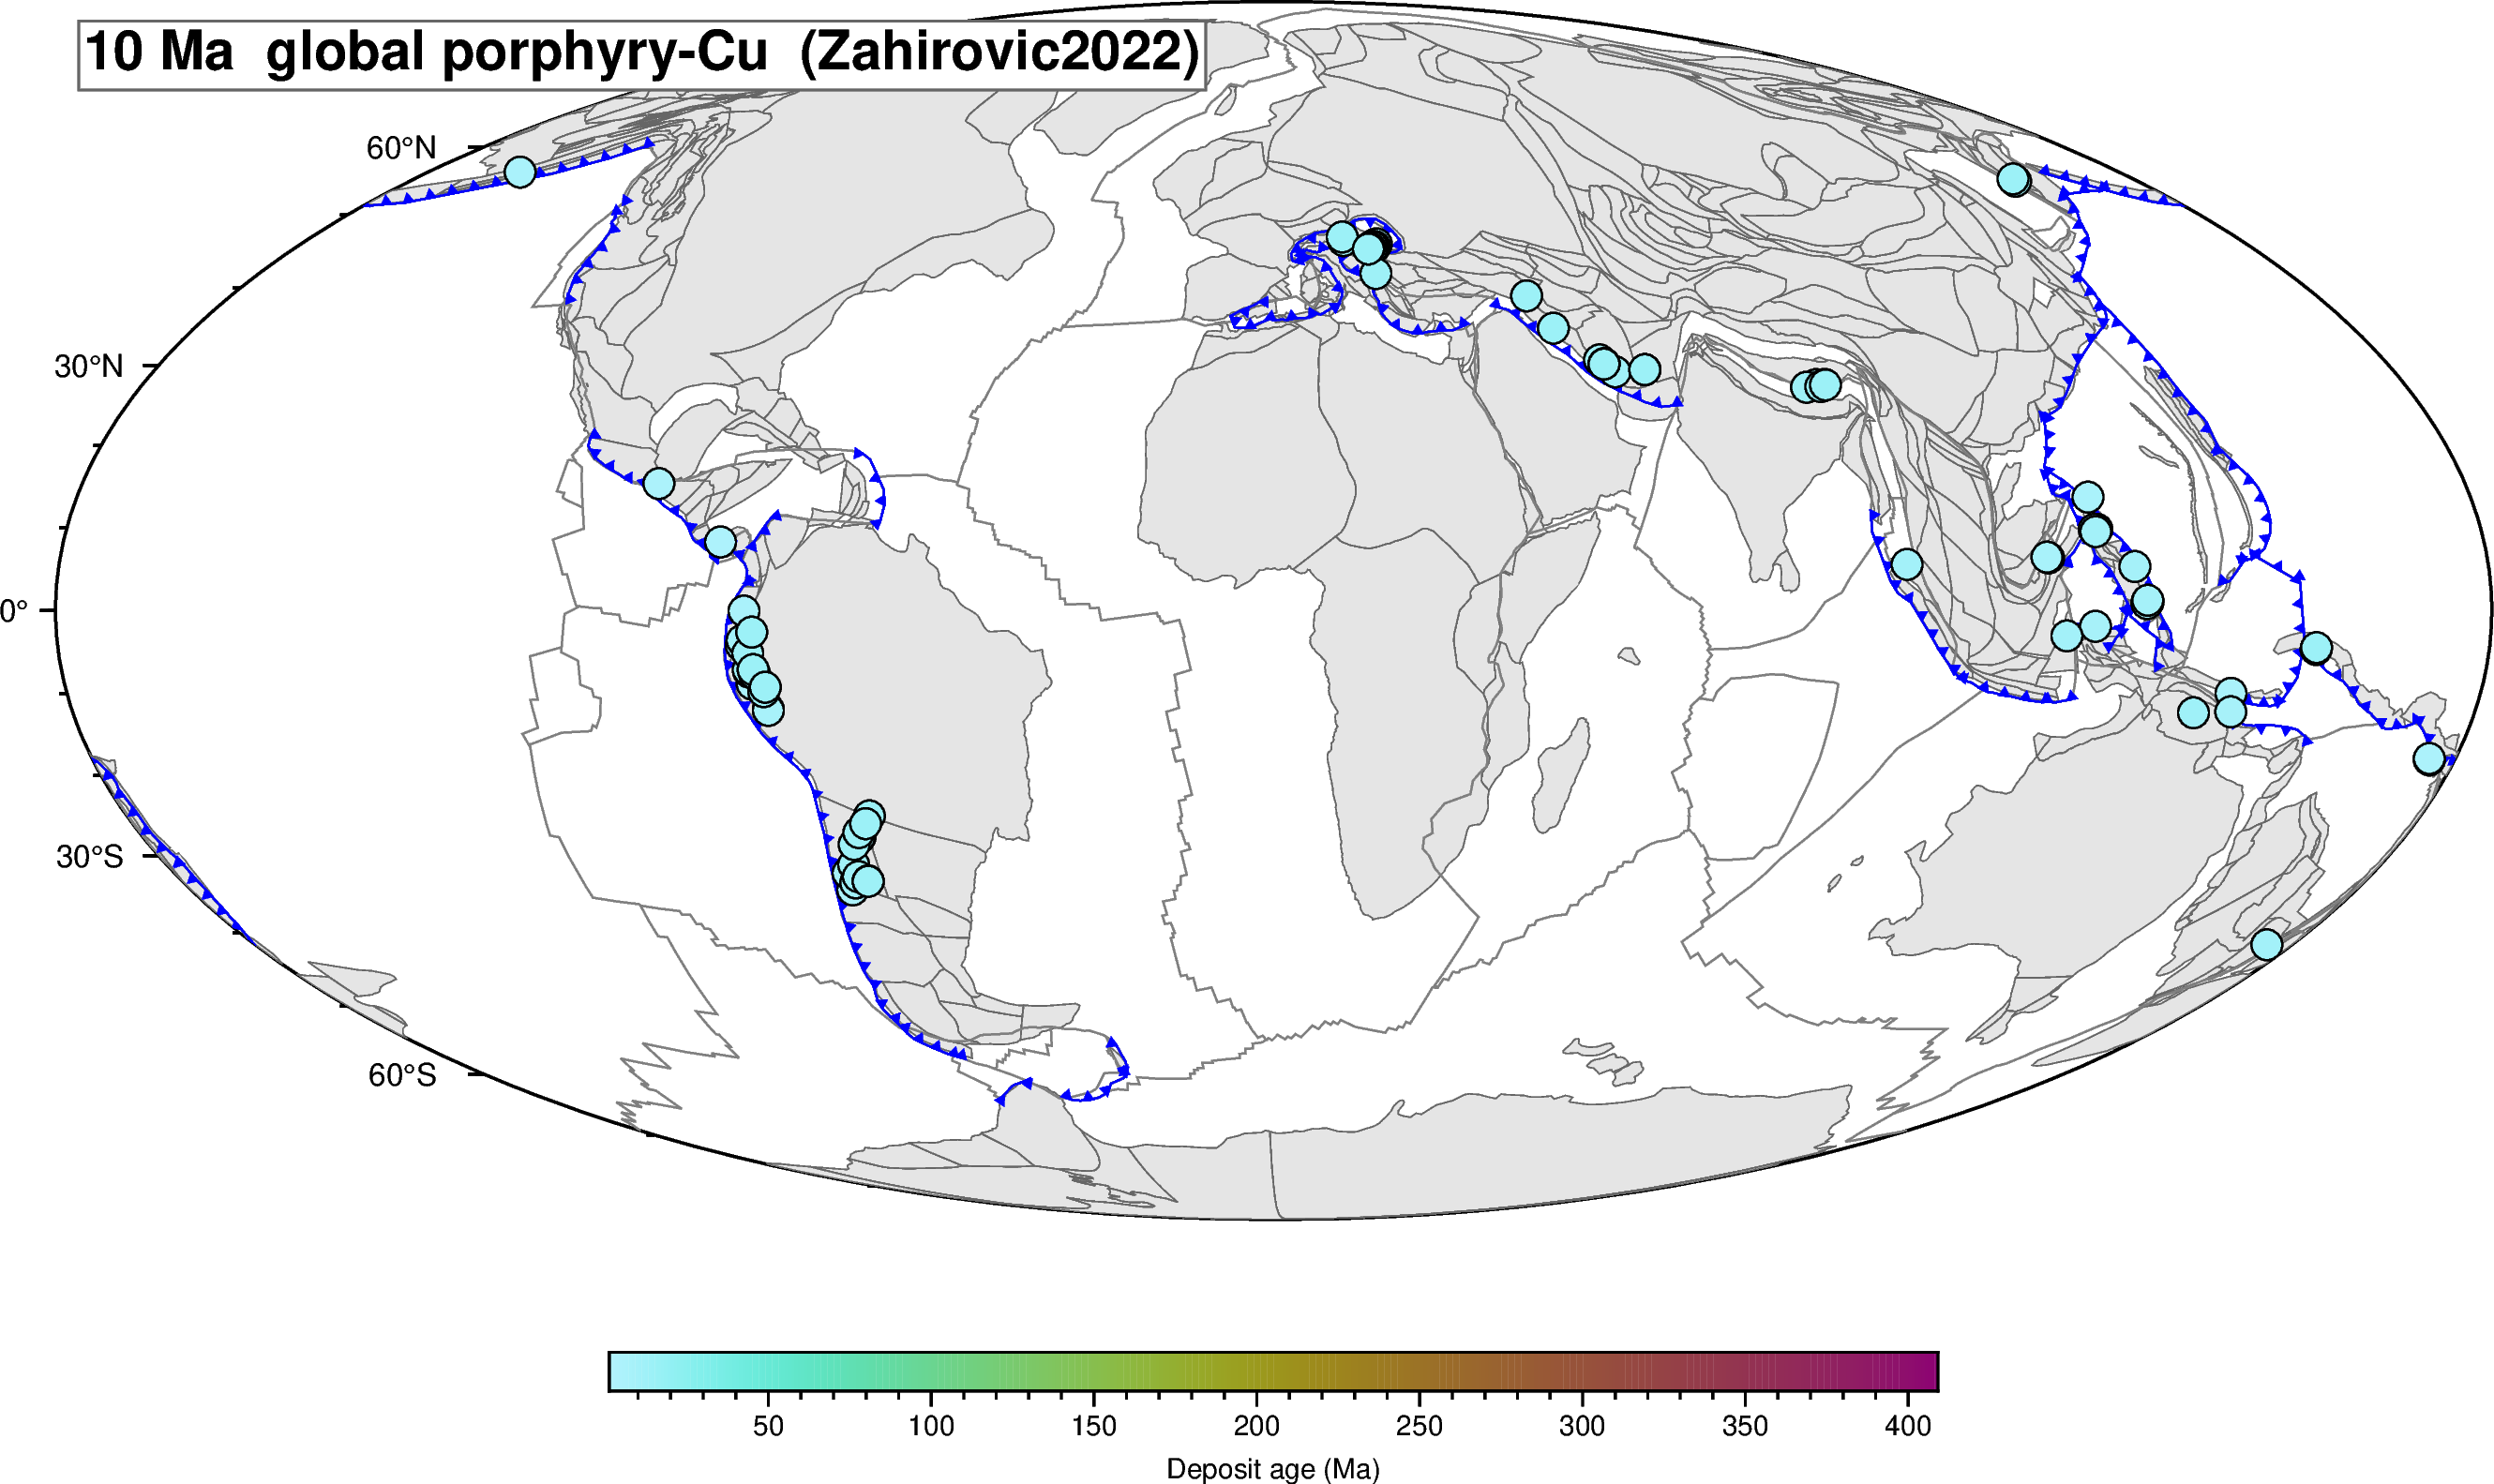

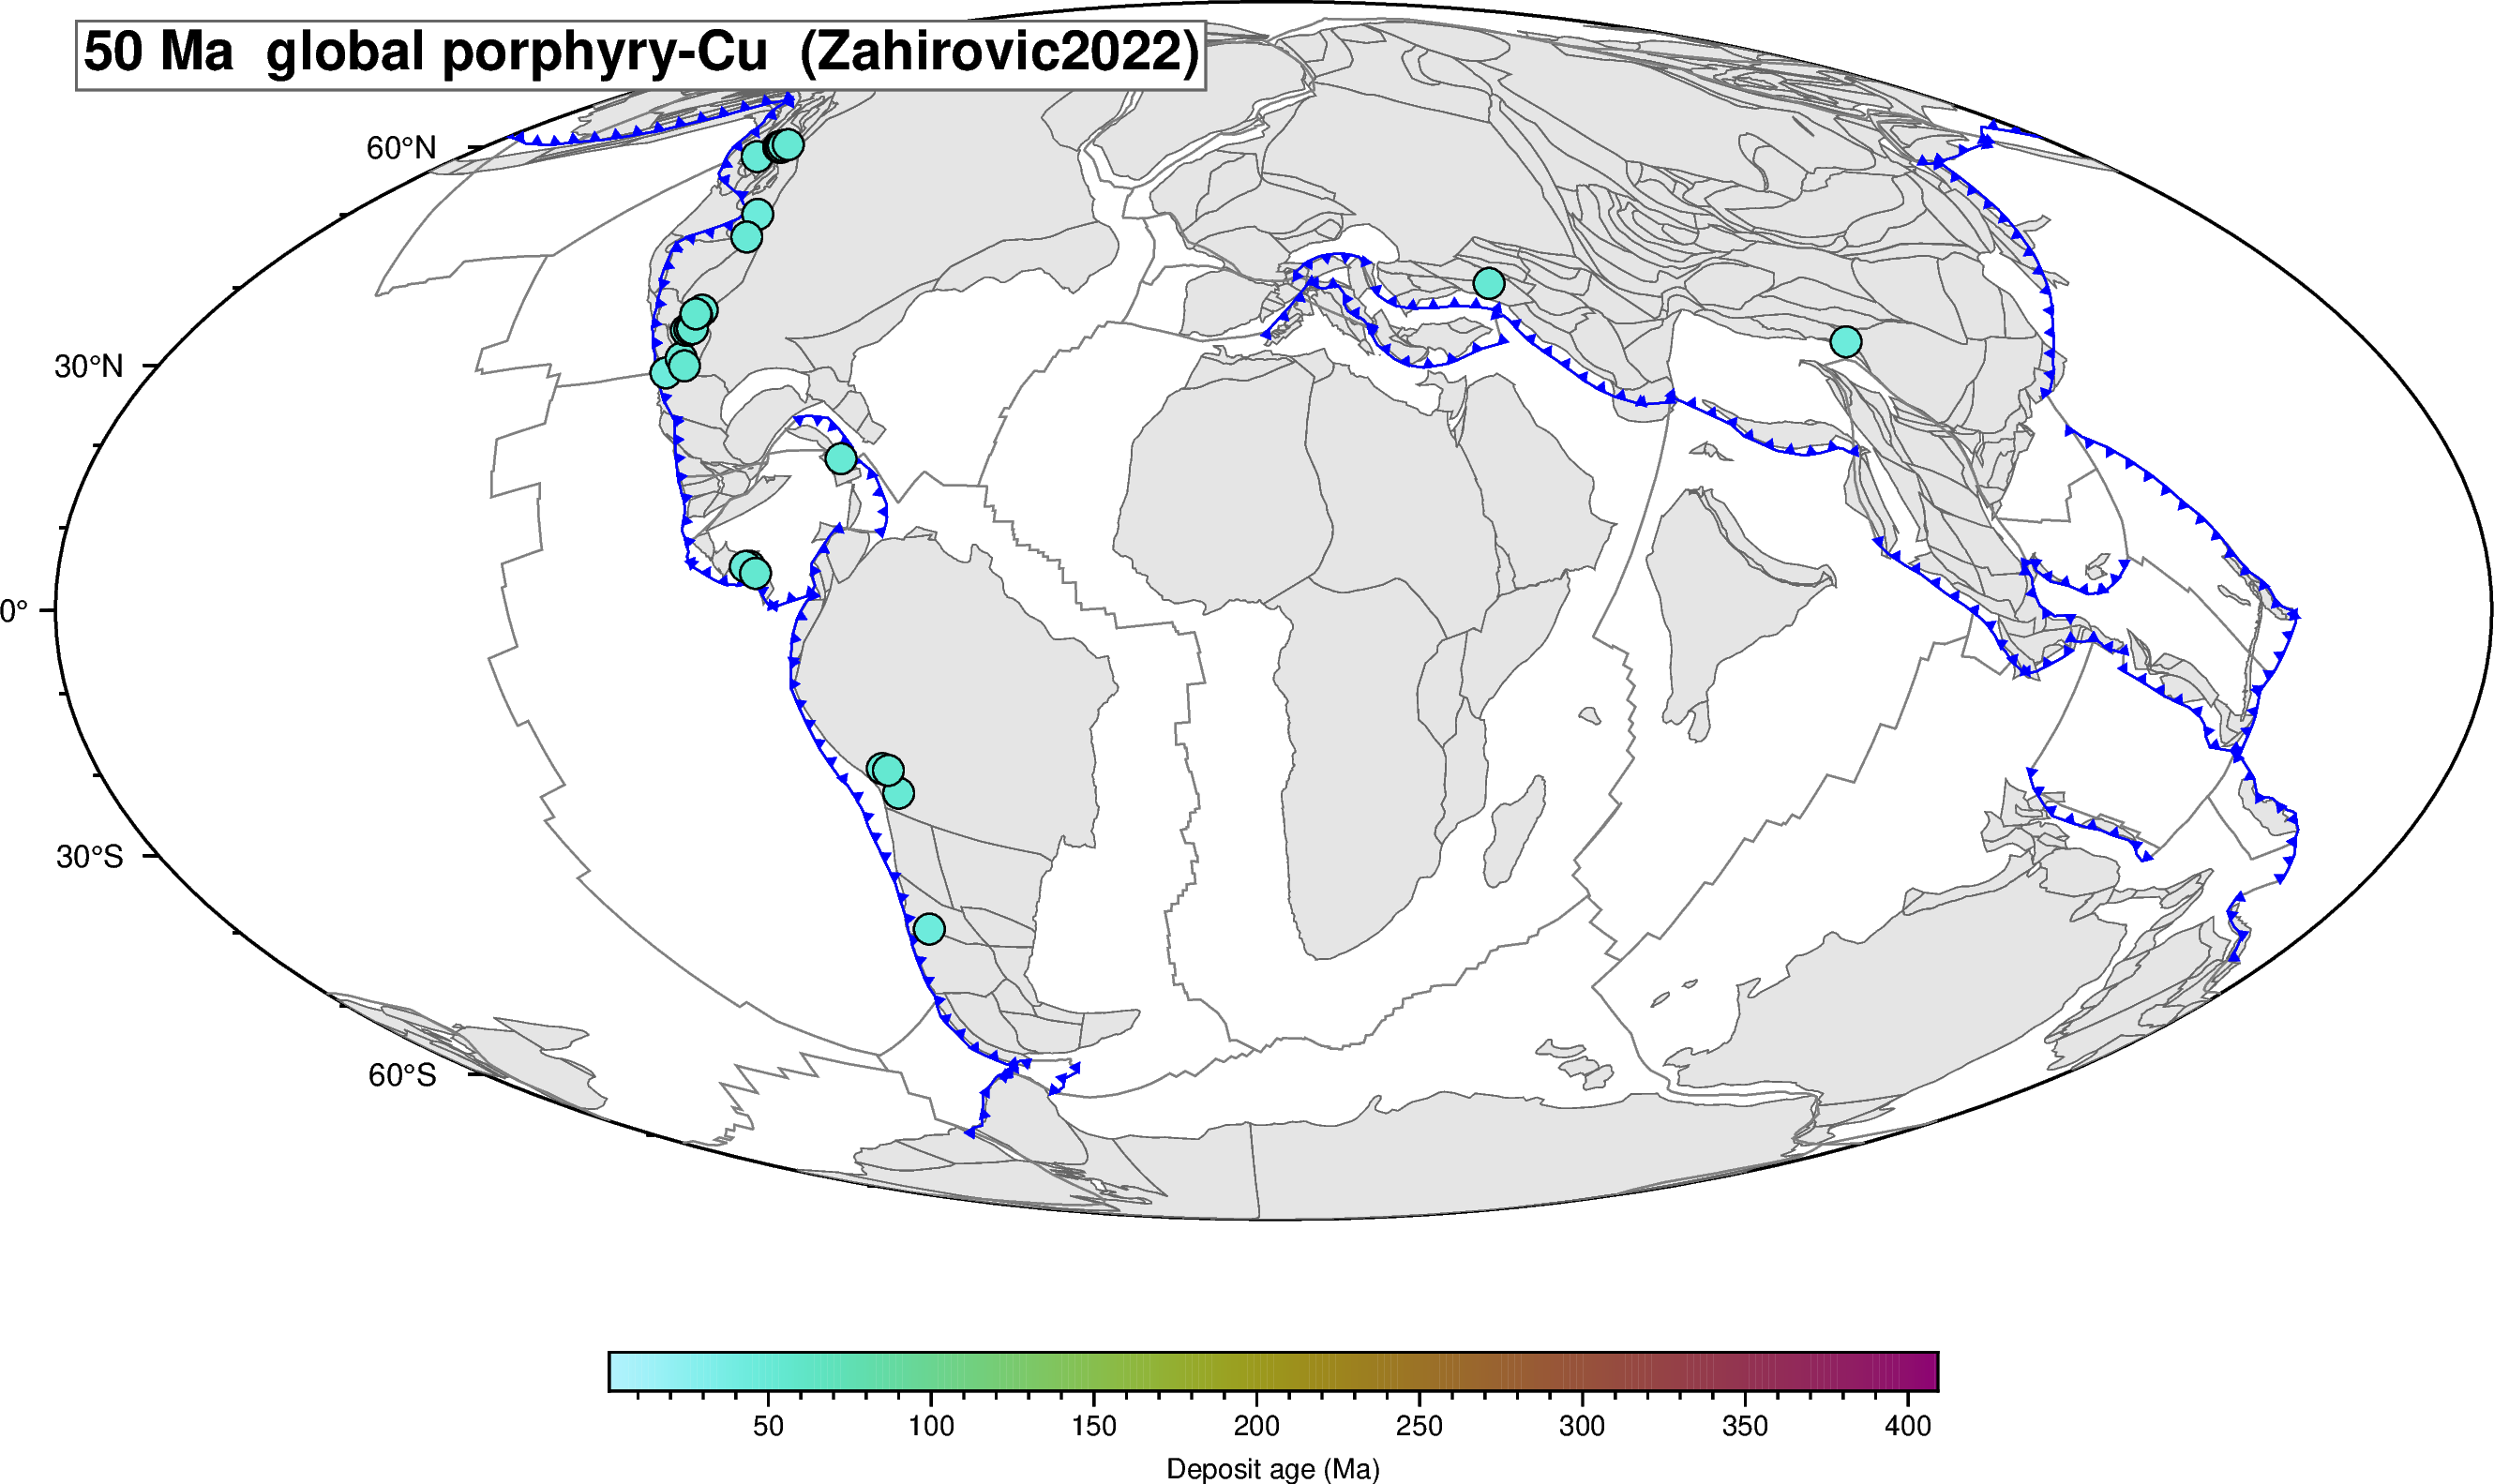

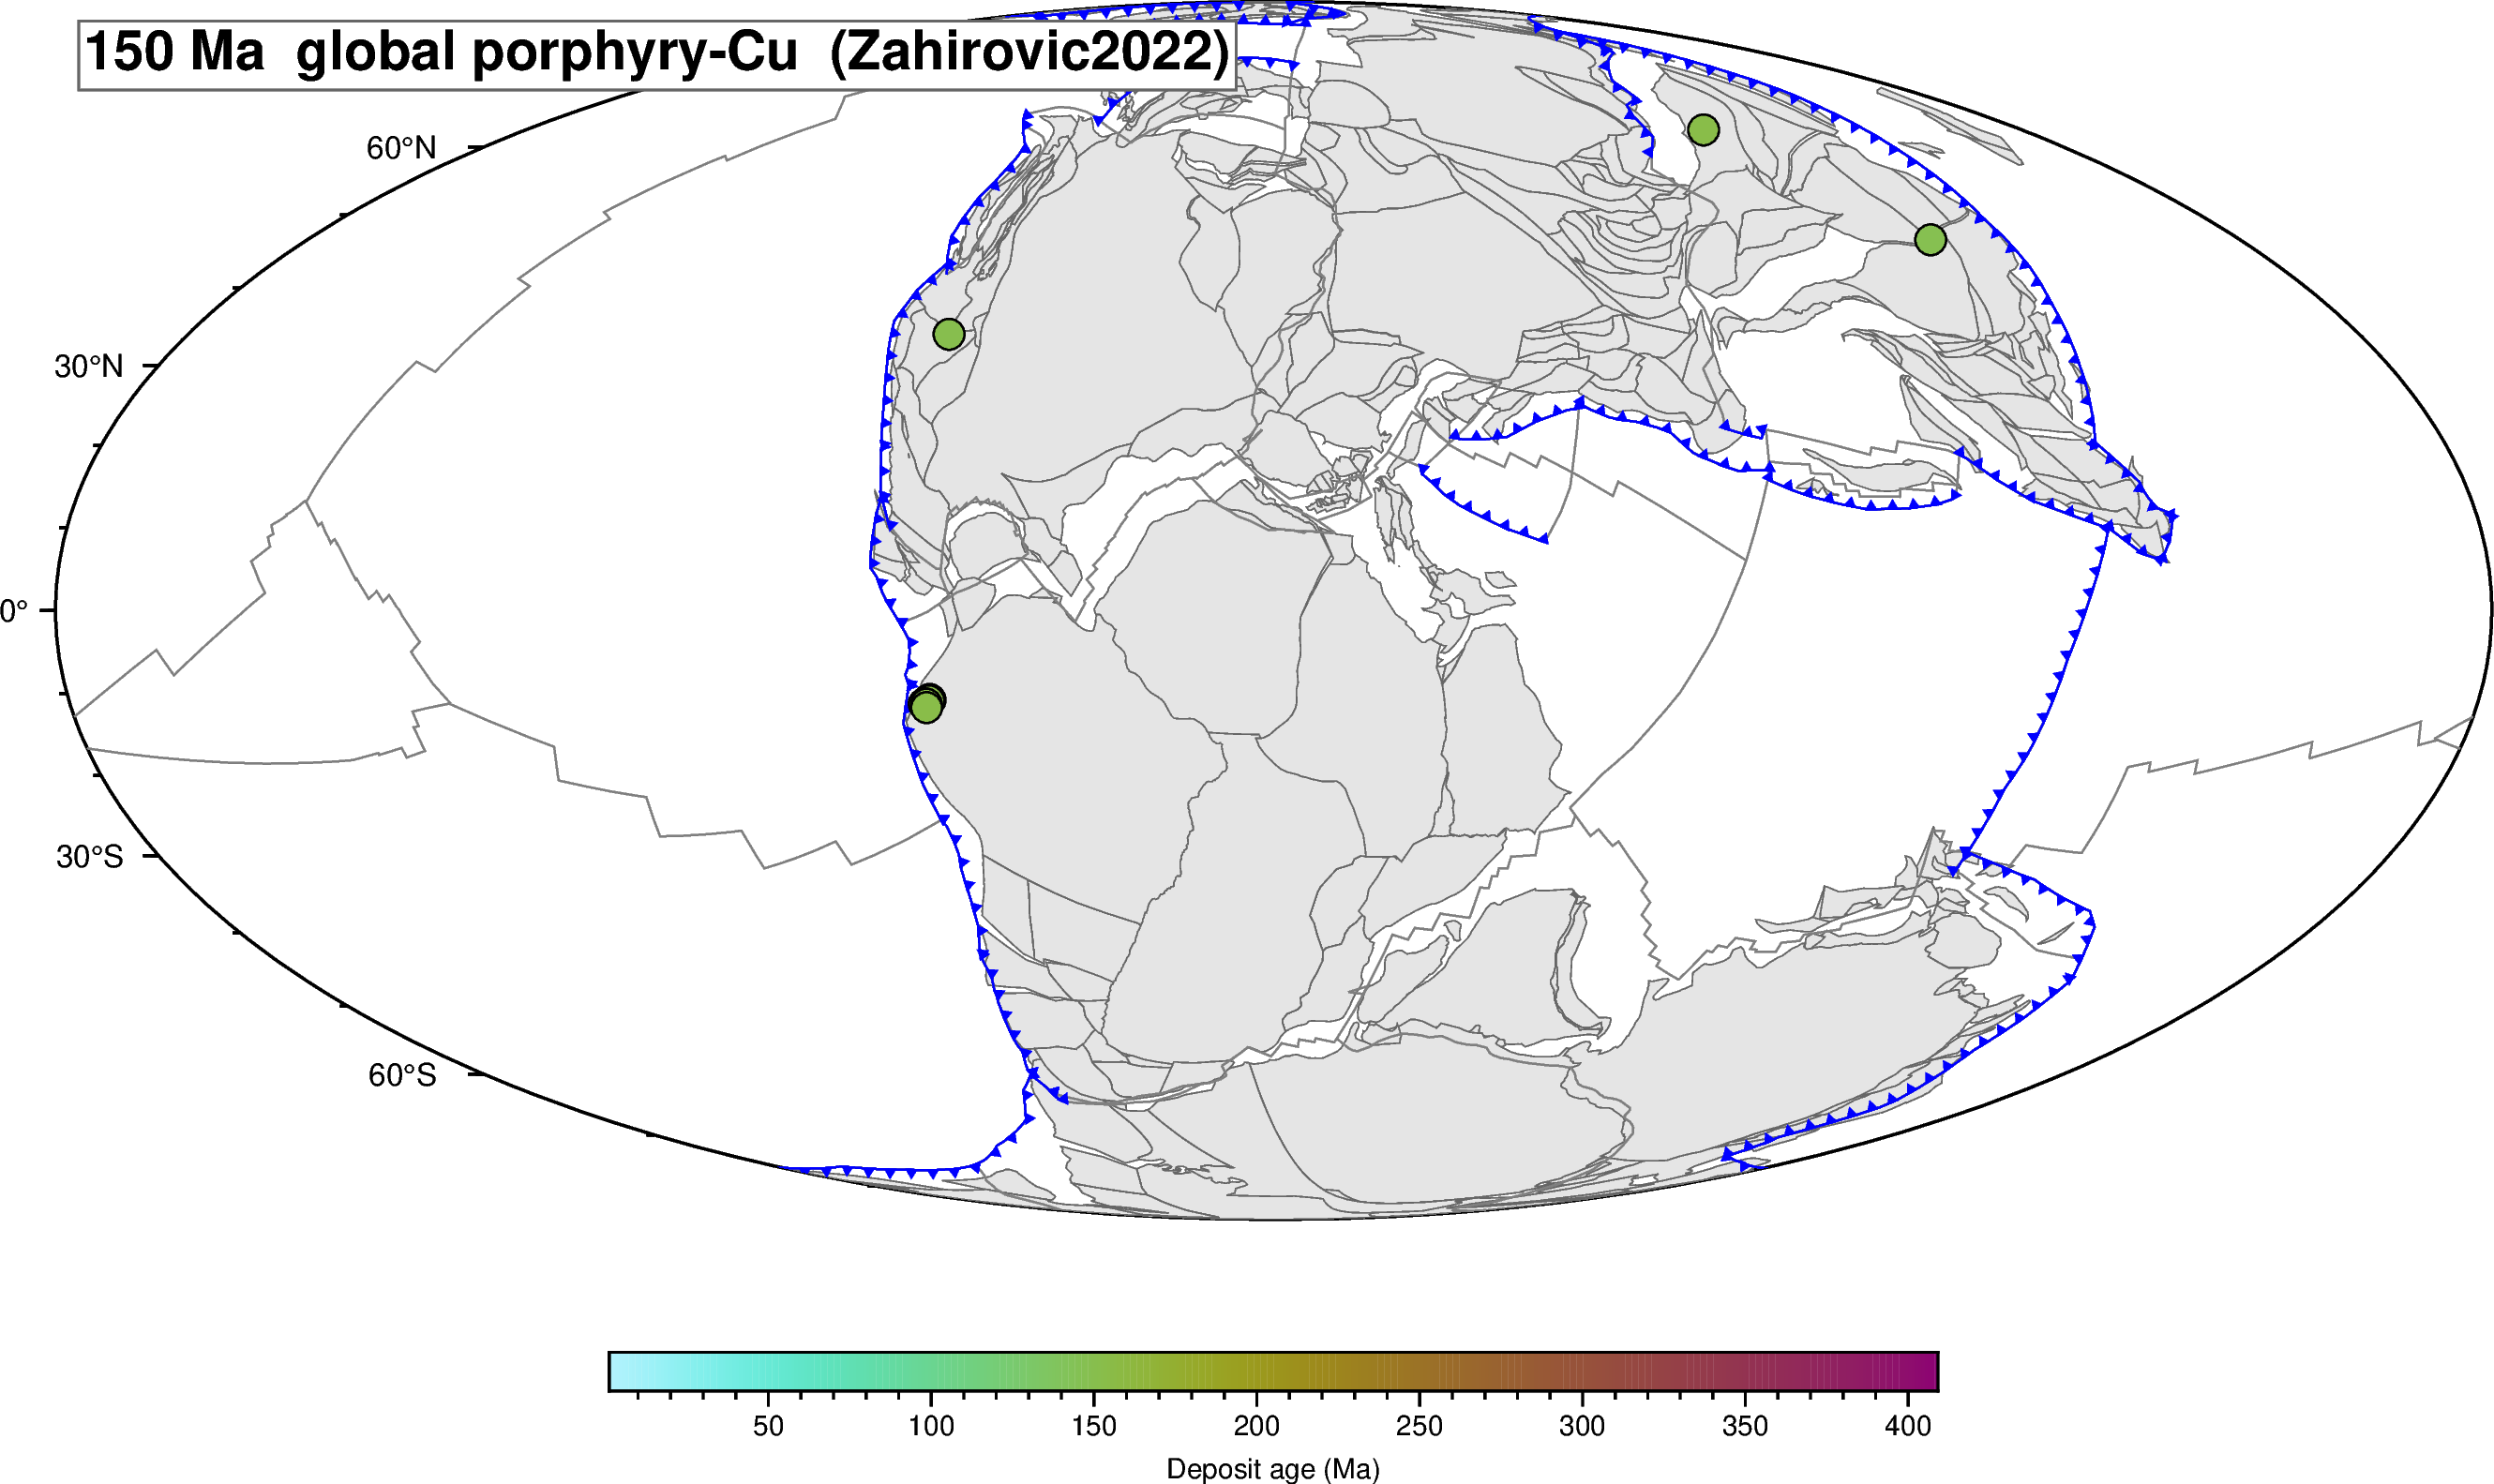

In [6]:
# Cell 5 — render

for t in SNAPSHOT_TIMES:
    gplot = gplately.PlotTopologies(
        plate_reconstruction=recon,
        coastlines=model.get_coastlines(),
        continents=model.get_continental_polygons(),
        COBs=model.get_COBs(), time=float(t),
        plot_engine=gplately.PygmtPlotEngine(),
        )
    window = dep[(dep.age_ma >= t - 5) & (dep.age_ma <= t + 5)]

    fig = pygmt.Figure()
    fig.basemap(region="d", projection="W0/22c", frame=["af"])
    gplot.plot_continents(fig, fill="gray90", pen="0.3p,gray40")
    gplot.plot_all_topological_sections(fig, pen="0.5p,gray50")
    (_tl, _tr) = gplot.get_subduction_direction()
    gplot.plot_subduction_teeth(fig, color="blue")

    if len(window) > 0:
        pygmt.makecpt(cmap="hawaii",
                      series=[dep.age_ma.min(), dep.age_ma.max(), 1], reverse=True)
        fig.plot(x=window["paleo_lon"], y=window["paleo_lat"],
                 style="c0.28c", fill=window["age_ma"], cmap=True,
                 pen="0.5p,black")
        fig.colorbar(frame="af+lDeposit age (Ma)",
                     position="JBC+w12c/0.35c+h+o0/1.2c")

    fig.text(text=f"{t:.0f} Ma  global porphyry-Cu  ({MODEL_NAME})",
             position="TL", offset="0.25c/-0.25c", justify="TL",
             font="14p,Helvetica-Bold,black",
             fill="white", pen="0.6p,gray40")
    fig.show(width=1100)
    display(HTML('<div style="height:1cm"></div>'))


## 5. Distance + convergence-rate envelope

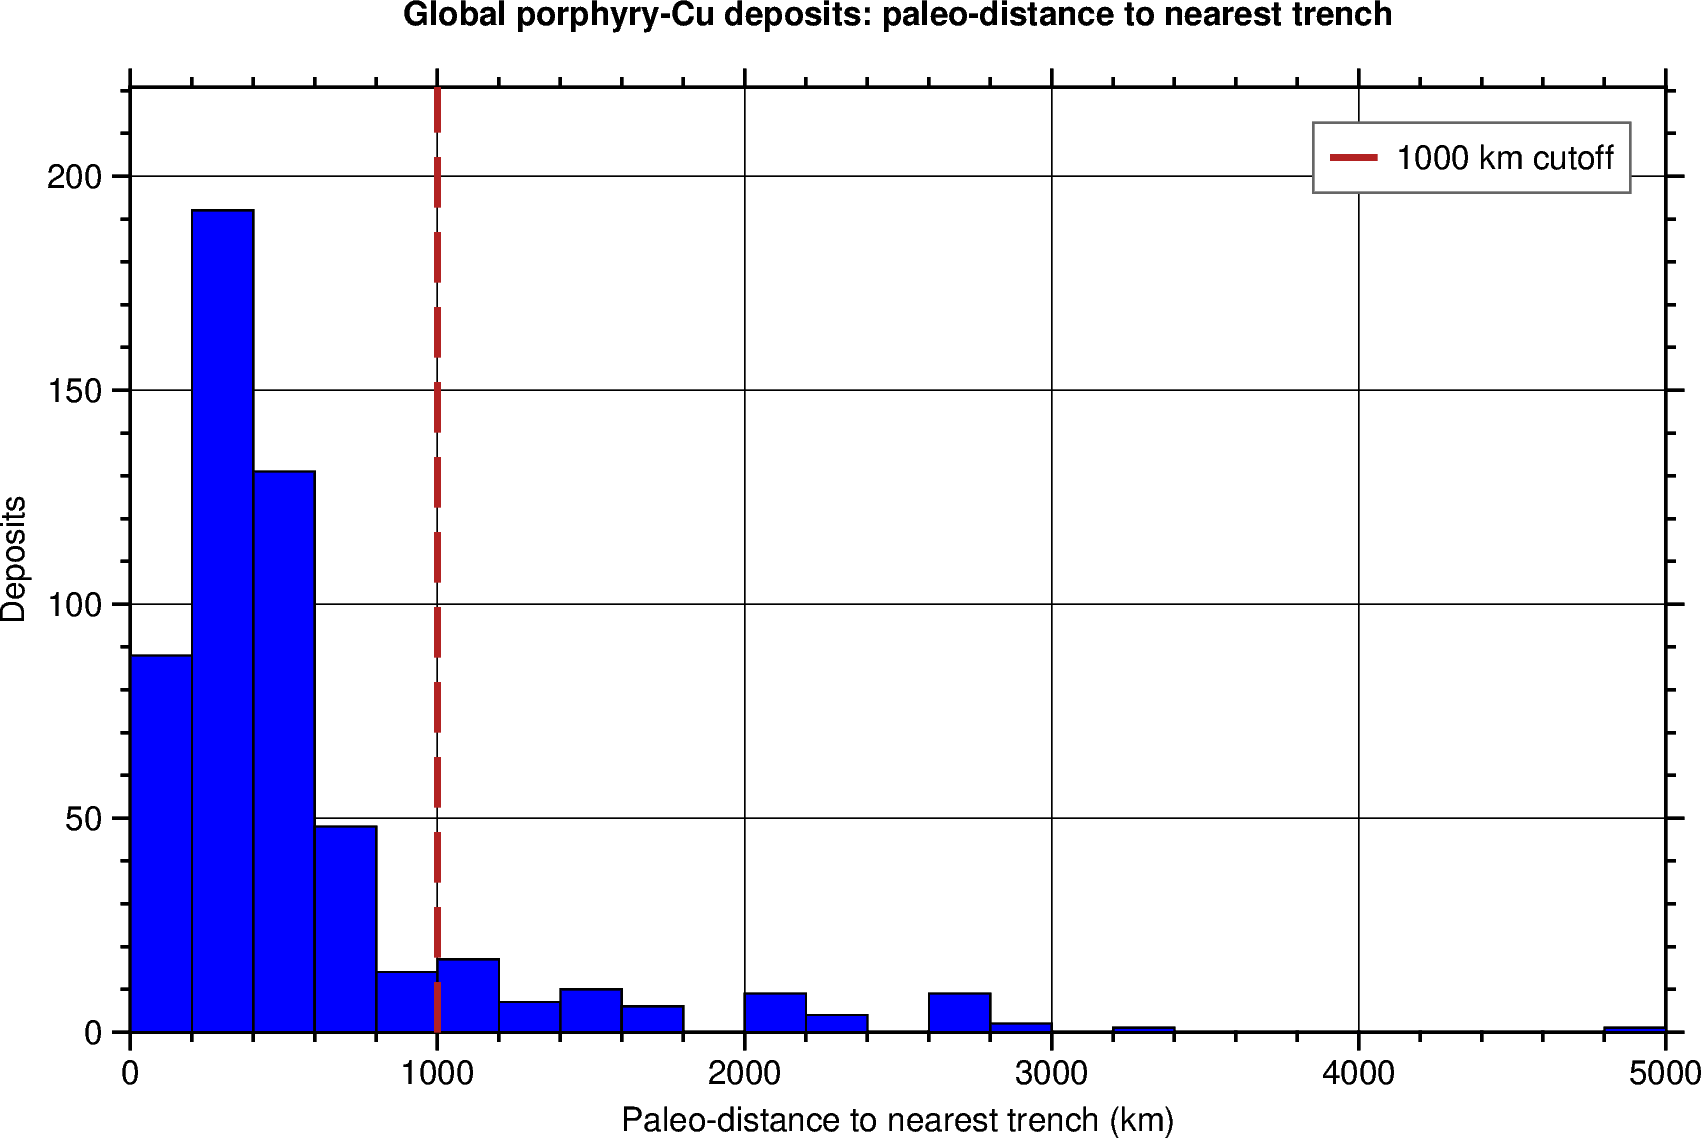

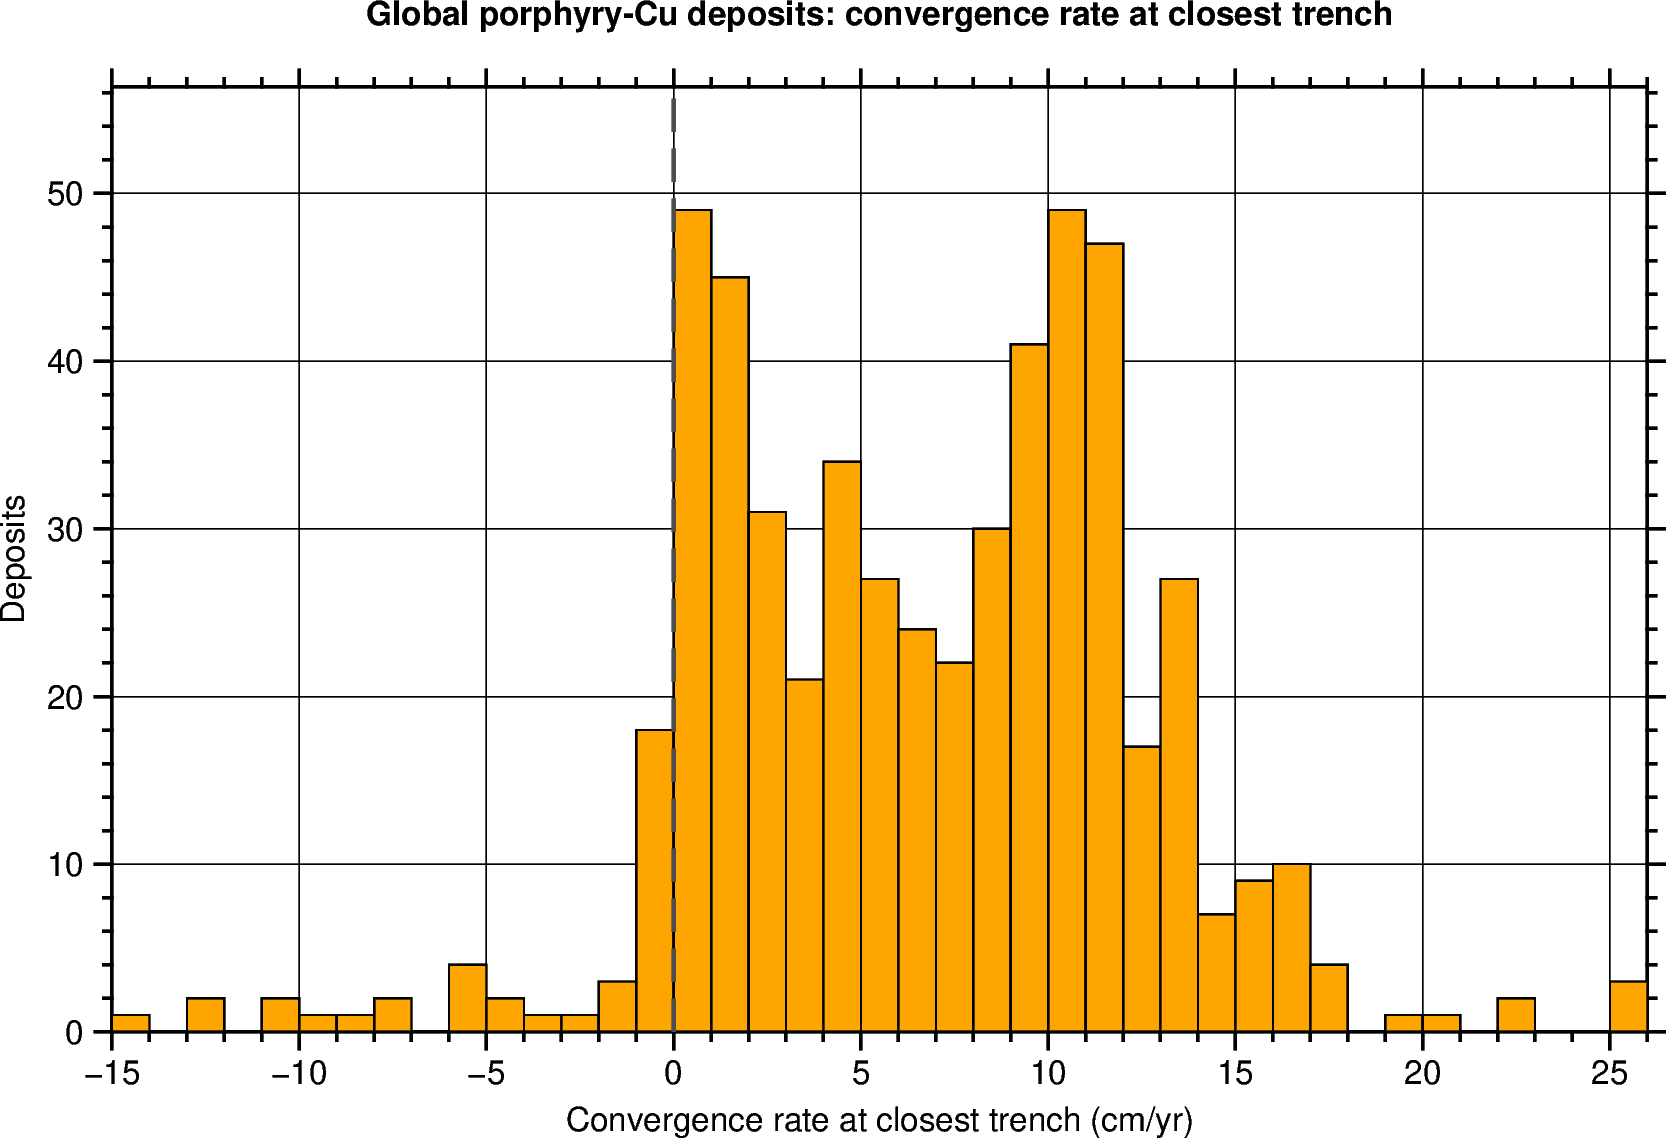

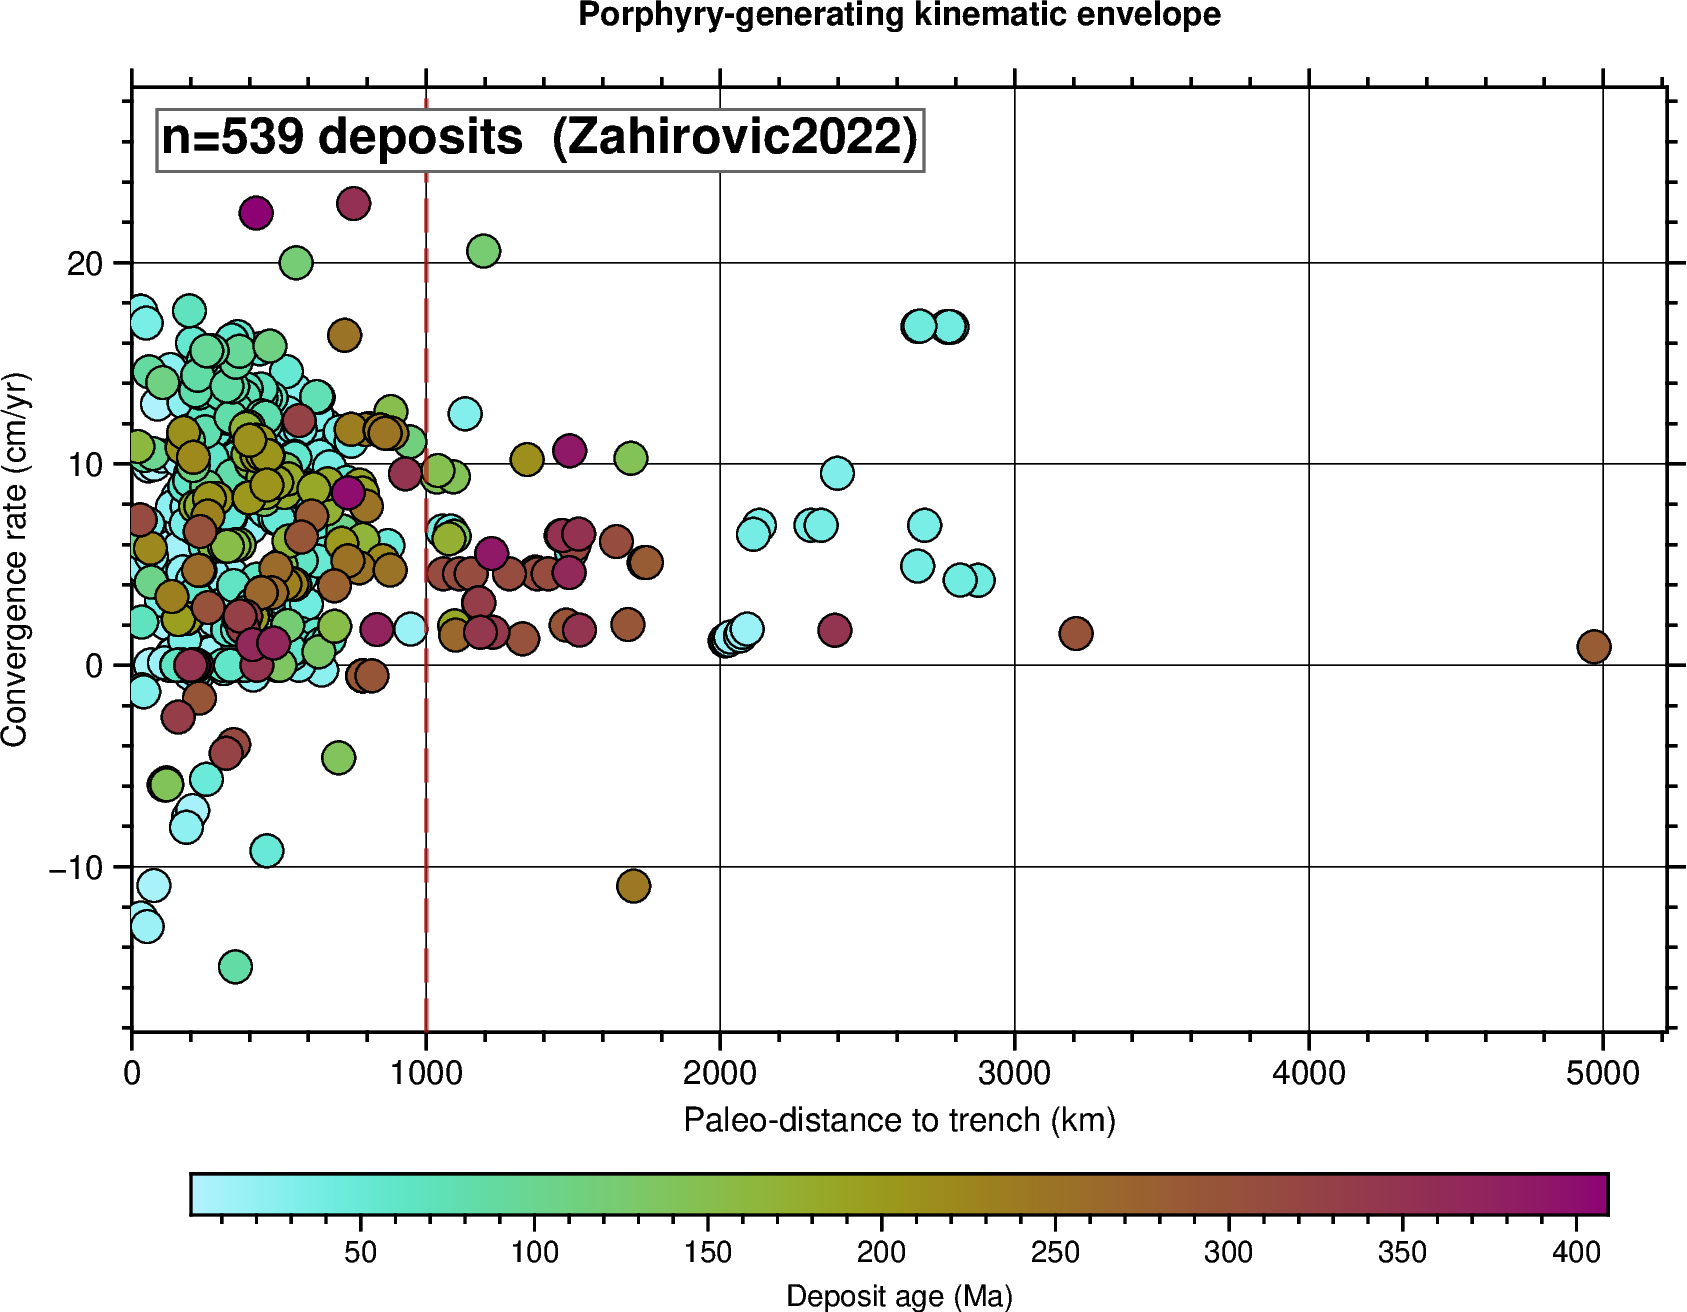

In [7]:
# Cell 6 — kinematic envelope: histogram + bivariate scatter
# One pygmt.Figure() per panel (house style — no pygmt.subplot).
valid = dep.dropna(subset=["trench_dist_km","conv_rate_cmyr"])

# --- Panel A: paleo-distance-to-trench histogram --------------------------
# bins cover every deposit (no silent clipping)
dist_bins = np.arange(0, 200 * (np.ceil(valid.trench_dist_km.max() / 200) + 1), 200)
dist_hist, dist_edges = np.histogram(valid.trench_dist_km, bins=dist_bins)
dist_centres = 0.5 * (dist_edges[:-1] + dist_edges[1:])
dist_width   = dist_edges[1] - dist_edges[0]
dist_y_max   = float(dist_hist.max()) * 1.15

fig = pygmt.Figure()
fig.basemap(region=[0, dist_edges[-1], 0, dist_y_max],
            projection="X13c/8c",
            frame=["WSne+tGlobal porphyry-Cu deposits: paleo-distance to nearest trench",
                   "xafg+lPaleo-distance to nearest trench (km)",
                   "yafg+lDeposits"])
fig.plot(x=dist_centres, y=dist_hist, style=f"b{dist_width}u+B0",
         fill="blue", pen="0.4p,black")
fig.plot(x=[NEAR_TRENCH_KM, NEAR_TRENCH_KM], y=[0, dist_y_max],
         pen="1.5p,firebrick,-", label=f"{NEAR_TRENCH_KM:.0f} km cutoff")
fig.legend(position="JTR+jTR+o0.3c/0.3c", box="+gwhite+p0.5p,gray40")
fig.show(width=900)
display(HTML('<div style="height:0.6cm"></div>'))

# --- Panel B: convergence-rate-at-closest-trench histogram ----------------
# 1 cm/yr bins over the full range; negative rates mean the nearest trench was diverging
rate_bins = np.arange(np.floor(valid.conv_rate_cmyr.min()), np.ceil(valid.conv_rate_cmyr.max()) + 1.0, 1.0)
rate_hist, rate_edges = np.histogram(valid.conv_rate_cmyr, bins=rate_bins)
rate_centres = 0.5 * (rate_edges[:-1] + rate_edges[1:])
rate_width   = rate_edges[1] - rate_edges[0]
rate_y_max   = float(rate_hist.max()) * 1.15

fig = pygmt.Figure()
fig.basemap(region=[rate_edges[0], rate_edges[-1], 0, rate_y_max],
            projection="X13c/8c",
            frame=["WSne+tGlobal porphyry-Cu deposits: convergence rate at closest trench",
                   "xafg+lConvergence rate at closest trench (cm/yr)",
                   "yafg+lDeposits"])
fig.plot(x=rate_centres, y=rate_hist, style=f"b{rate_width}u+B0",
         fill="orange", pen="0.4p,black")
fig.plot(x=[0, 0], y=[0, rate_y_max], pen="1.0p,gray30,-")
fig.show(width=900)
display(HTML('<div style="height:0.6cm"></div>'))

# --- Panel C: distance vs convergence rate, coloured by deposit age -------
# Region is data-driven (with matplotlib-style ~5-8% autoscale padding) so
# every point stays visible, including any far-field distances or the
# occasional negative (divergent) convergence-rate sample near a retreating
# trench segment — a fixed [0, 5000] window would silently clip those.
scatter_x_max = float(valid.trench_dist_km.max()) * 1.05
_rate_min, _rate_max = float(valid.conv_rate_cmyr.min()), float(valid.conv_rate_cmyr.max())
_rate_pad = 0.08 * (_rate_max - _rate_min)
scatter_y_lo = min(0.0, _rate_min - _rate_pad)
scatter_y_hi = _rate_max + _rate_pad

fig = pygmt.Figure()
fig.basemap(region=[0, scatter_x_max, scatter_y_lo, scatter_y_hi],
            projection="X13c/8c",
            frame=["WSne+tPorphyry-generating kinematic envelope",
                   "xafg+lPaleo-distance to trench (km)",
                   "yafg+lConvergence rate (cm/yr)"])
pygmt.makecpt(cmap="hawaii",
              series=[dep.age_ma.min(), dep.age_ma.max(), 1], reverse=True)
fig.plot(x=valid.trench_dist_km, y=valid.conv_rate_cmyr,
         style="c0.28c", fill=valid.age_ma, cmap=True, pen="0.4p,black")
fig.plot(x=[NEAR_TRENCH_KM, NEAR_TRENCH_KM], y=[scatter_y_lo, scatter_y_hi],
         pen="1.0p,firebrick@30,-")
fig.colorbar(frame="af+lDeposit age (Ma)",
             position="JBC+w12c/0.35c+h+o0/1.2c")
fig.text(text=f"n={len(valid)} deposits  ({MODEL_NAME})",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="12p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=900)


## Extend this

- **ML prospectivity.** The feature stack computed here — distance + convergence rate + age — is the kind of input used by the Butterworth et al. (2016) spatio-temporal classifier. Add slab obliquity, trench velocity, and overriding-plate identity from `tessellate_subduction_zones` columns 3–5, 7, and 9 for the full feature set.
- **Subtype filter.** Restrict to `commodity == "Cu-Au"` (or `"Cu-Mo"`) and re-run, then compare the kinematic envelopes of the three subtypes.
- **Weight by size.** `tonnage_mt * cu_pct / 100` is the contained copper (Mt) of the 371 deposits with a reported tonnage; weight the histograms by it to see where most of the metal formed.
- **Cross-reference K01 and K05.** K01 is a regional SW-Pacific zoom on this same workflow; K05 is the Cordilleran zoom. K02 generalises both.

## References

- Butterworth, N., Steinberg, D., Müller, R.D., Williams, S., Merdith, A.S. & Hardy, S. (2016). Tectonic environments of South American porphyry copper magmatism through time revealed by spatiotemporal data mining. *Tectonics* 35(12), 2847-2862. https://doi.org/10.1002/2016TC004289
- Sillitoe, R.H. (2010). Porphyry copper systems. *Economic Geology* 105(1), 3–41. https://doi.org/10.2113/gsecongeo.105.1.3
- Mutschler, F.E., Ludington, S. & Bookstrom, A.A. (1999). Giant porphyry-related metal camps of the world — a database. *USGS Open-File Report* 99-556.
- Singer, D.A., Berger, V.I. & Moring, B.C. (2008). Porphyry copper deposits of the world: Database and grade and tonnage models. *USGS Open-File Report* 2008-1155.
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11(1), 3–10. https://doi.org/10.1002/gdj3.185
- Tian, D., Uieda, L., Leong, W.J., et al. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515
